In [1]:
import cv2
image=cv2.imread('data/image2.jpg')
image_gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
# image ta onek boro (6000x4110), tai screen e fit korar jonno choto kore nicchi
h, w = image.shape[:2]
h1,w1 = image_gray.shape[:2]
scale=800/h
scale2 = 800 / h1
small = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
small_gray = cv2.resize(image_gray, (int(w1 * scale2), int(h1 * scale2)), interpolation=cv2.INTER_AREA)
print('image shape:', image.shape)
print('image_gray shape:', image_gray.shape)
cv2.imshow('output', small) 
cv2.imshow('output_gray', small_gray)  # default AUTOSIZE: image tene boro-choto kore na
cv2.waitKey(0)                # window e click kore je kono key chapo
cv2.destroyAllWindows()


image shape: (6000, 4110, 3)
image_gray shape: (6000, 4110)


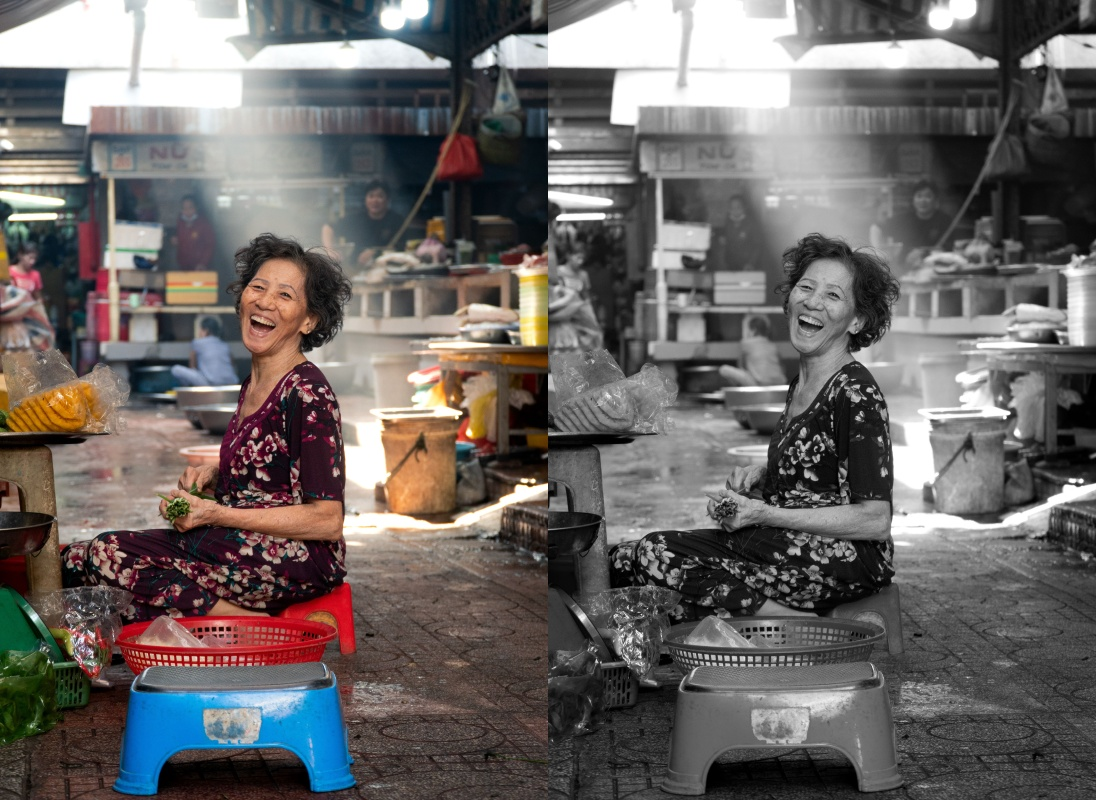

In [2]:
from IPython.display import Image, display
import numpy as np

# gray image e 1 ta channel, color image e 3 ta channel.
# pasapasi jora lagate hole duitar channel soman hote hobe, tai gray ke 3 channel e convert korchi
small_gray_3ch = cv2.cvtColor(small_gray, cv2.COLOR_GRAY2BGR)

# np.hstack = horizontally (pasapasi) jora lagay. (np.vstack dile upore-niche hoto)
# shorto: duita image er height soman hote hobe (ekhane duitai 800)
side_by_side = np.hstack((small, small_gray_3ch))

ok, buf = cv2.imencode('.jpg', side_by_side)
display(Image(data=buf.tobytes()))


small_blur shape: (800, 548)


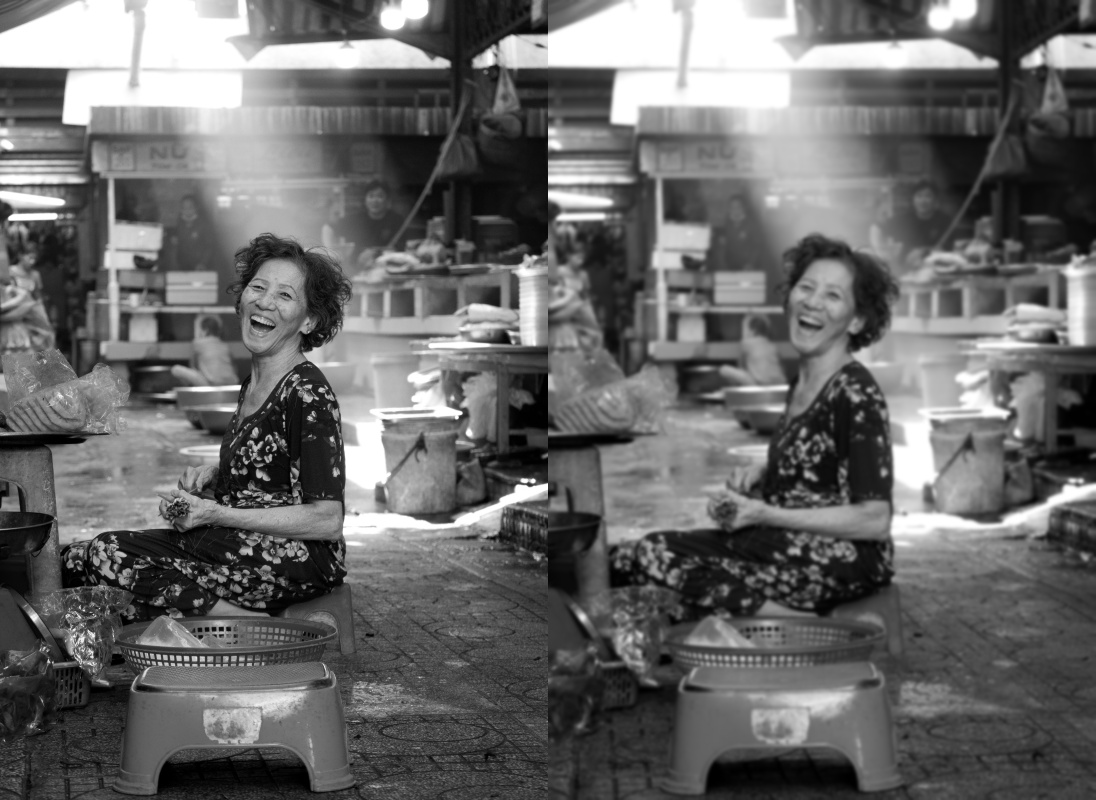

In [3]:
# age resize, tarpor blur: choto image e blur korle effect ta chokhe pore.
# (6000px er boro image e (5,5) blur korle, pore choto korar somoy blur ta prai muche jay)
# kernel size (ksize) odd number hote hobe: (3,3), (5,5), (15,15) ... jto boro, toto beshi blur
small_blur = cv2.GaussianBlur(small_gray, (7, 7), 0)
print('small_blur shape:', small_blur.shape)

# original ar blur pasapasi jora lagachhi
side_by_side_blur = np.hstack((small_gray, small_blur))

# cv2.imshow alada window khole, notebook er niche output dekhay na.
# niche dekhate hole IPython er display() lagbe (cell 2 er moto)
ok, buf_blur = cv2.imencode('.jpg', side_by_side_blur)
display(Image(data=buf_blur.tobytes()))


In [4]:
### 3. canny filter: edge detection
image_canny = cv2.Canny(small_blur, 100, 200)  # threshold1=100, threshold2=200
print('image_canny shape:', image_canny.shape)
cv2.imshow('output_canny', image_canny)
cv2.waitKey(0)
cv2.destroyAllWindows()

image_canny shape: (800, 548)
